# 47 · 양방향 encoder와 masked language modeling

`[MASK] pear is red`의 첫 색을 맞히려면 오른쪽의 `red`를 읽을 수 있습니다. 앞부분만으로 다음 token을 예측한45번과 달리, 이번에는 **입력 일부를 바꾸고 원래 token을 복원**합니다.

- 준비물: [44 token·문서 경계](44_tokenization.ipynb), [45 전체 block 미분](45_decoder_gpt.ipynb), [20 padding mask](../03_구조조합/20_sequence_encoder_decoder.ipynb)입니다.
- 순서: ① 읽을 수 있는 문맥 → ② 선택과 corruption → ③ 선택 CE와 전체 backward → ④ MLM/next-token 실제 학습 → ⑤ 독립 빈칸 복원·경계 검사입니다.
- 범위: 작은 한 head·한 pre-LN block·tanh FFN을 독립 학습합니다. BERT의 규모·NSP·segment embedding·세부 구조를 재현하지 않습니다. 사전학습 가중치를 사용하지 않습니다.

> **용어** · **MLM(masked language modeling)**은 선택한 token의 원래 값을 손상된 문맥에서 예측하는 목적입니다. **양방향(bidirectional)**은 유효한 왼쪽·오른쪽 token을 모두 읽는다는 뜻입니다. **corruption**은 학습 입력 일부를 MASK나 다른 token으로 바꾸는 규칙입니다. 손실 정답은 바꾸기 전 원문입니다.

### 읽는 법

| 표시 | 대상 |
|---|---|
| 🔑 핵심 | 읽기 범위·정답·미분의 연결 |
| 🔍 확인 | 실제 값·손계산·경계 |
| 📎 참고 | 출처·범위·코드 |
| ✏️ 연습 | 한두 줄 재구성 |

**이 노트북에서 반드시 가져갈 세 가지**

1. attention mask와 loss mask는 서로 다른 배열입니다.
2. 선택한 위치가 원래 token 그대로여도 손실에 포함합니다.
3. MLM 복원은 자기회귀 문장 확률이나 정답 없는 자유 생성과 같은 문제가 아닙니다.

[그림 보조 코드](../../src/utils/masked_language_model_plots.py) · [학습 경로](../../docs/CURRICULUM.md)

In [1]:
# 준비 셀: 모델 상태와 데이터는 이 notebook 안에서 새로 만듭니다.
import sys
from pathlib import Path
import numpy as np
project_root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient
from src.utils.masked_language_model_plots import (
    plot_context_masks,plot_corruption,plot_selected_loss,plot_information_access,plot_fill,plot_mlm_learning,
)
setup_plots()

'Arial Unicode MS'

## 🔑 1. 같은 token열에서도 읽을 수 있는 위치가 다릅니다

**이 절에서 가져갈 것:** MLM의 양방향 attention은 미래도 읽지만 padding은 여전히 제외합니다.

과일 문장 `[red,pear,is,red]`의 첫 `red`를 가리면 마지막 색이 단서입니다. 자기회귀 모델은 첫 색을 예측할 때 이 단서를 아직 볼 수 없습니다.

유효 위치 $v_i$에서 양방향 허용은 $A_{ij}=v_iv_j$이고, causal 허용은 여기에 $\mathbf1[j\le i]$를 곱합니다. 둘 다 `(N,T,T)`이고 softmax는 key축 j에서 계산합니다. loss mask `(N,T)`는 뒤에서 별도로 정합니다.

PAD=0, BOS=1, EOS=2, MASK=3, 본문 ID는4부터입니다. MASK는 유효 입력이므로 attention에서 제외하지 않습니다. 가린 token의 원래 값은 모델 입력에 넣지 않고 target 배열에만 남깁니다.

> **용어** · **MASK token**은 특정 원래 단어가 아니라 빈칸임을 알리는 학습 가능한 embedding 행입니다. **target**은 원래 원문 token이고, **selected mask**는 그 target의 손실을 계산할 위치입니다.
>
> **코드** · `valid[:,None] & valid[None,:]`는 모든 query–key 조합을 검사합니다. `np.tril`을 곱하면 causal 범위가 됩니다.

In [2]:
context_tokens=np.array([1,3,8,12,4,2,0])
context_valid=context_tokens!=0
bidirectional=context_valid[:,None]&context_valid[None,:]
causal=bidirectional&np.tril(np.ones((7,7),dtype=bool))

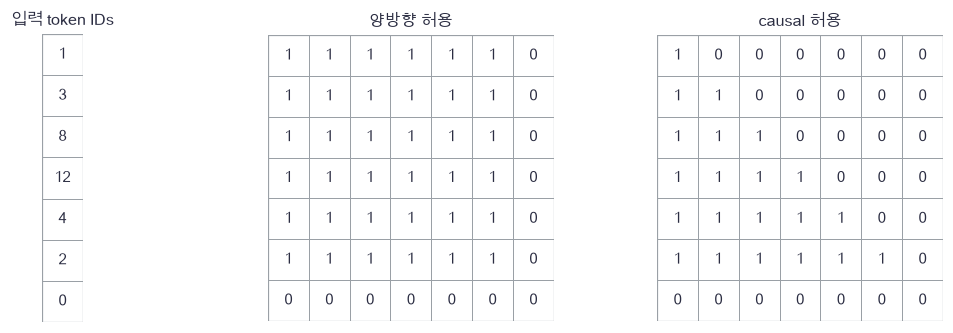

In [3]:
plot_context_masks(context_tokens,bidirectional,causal)

🔍 **확인** · 양방향 행렬의 첫 MASK 행은 뒤의 색을 읽습니다. 마지막 PAD 행·열은 모두0입니다. 이름이 mask라는 이유로 MASK token을 padding처럼 없애면 빈칸 표현을 학습하는 문제까지 바뀝니다.

In [4]:
def context_mask(valid,causal=False):
    """유효 query/key를 남기고 필요할 때만 미래 key를 막습니다."""
    allowed=valid[:,:,None]&valid[:,None,:]
    if causal:
        allowed=allowed&np.tril(np.ones((valid.shape[1],valid.shape[1]),dtype=bool))[None,:,:]
    return allowed

In [5]:
np.testing.assert_array_equal(context_mask(context_valid[None,:])[0],bidirectional)  # 검산: 양방향 직접 계산
np.testing.assert_array_equal(context_mask(context_valid[None,:],True)[0],causal)  # 검산: causal 직접 계산
assert bidirectional[1,4], 'MLM MASK 위치는 오른쪽 색을 읽을 수 있습니다'
assert not causal[1,4], 'causal 위치는 오른쪽 색을 읽을 수 없습니다'
print('MASK token·padding·양방향/causal 읽기 범위 검산 통과')

MASK token·padding·양방향/causal 읽기 범위 검산 통과


### ✏️ 연습 1 · 유효한 양방향 연결

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

valid 한 행에서 모든 유효 query/key를 잇는 allowed를 채우세요.

In [6]:
def exercise_bidirectional(valid):
    """유효한 양방향 연결의 계산을 완성합니다."""
    ### 구현할 내용: valid 한 행에서 모든 유효 query/key를 잇는 allowed를 채우세요.
    raise NotImplementedError
    return allowed

In [7]:
def check_bidirectional(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.array([1,1,0],dtype=bool)),[[1,1,0],[1,1,0],[0,0,0]])  # 검산: PAD 행·열0
    print("연습 1 통과")

run_check(check_bidirectional, exercise_bidirectional, hint="유효한 양방향 연결의 수식과 축을 확인하세요.")

☐ exercise_bidirectional: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 유효한 양방향 연결의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
allowed = valid[:,None] & valid[None,:]
```

</details>

## 🔑 2. 선택한 위치와 바꾼 위치를 구분합니다

**이 절에서 가져갈 것:** 선택된 token은 MASK·랜덤·그대로의 세 경우 모두 원래 target으로 학습합니다.

선택 위치 세 개의 난수가 .1,.85,.95라면 첫째는 MASK, 둘째는 랜덤 본문 token, 셋째는 원래 값을 유지합니다. 셋째도 선택된 문제이므로 손실 분모에 포함합니다. `corrupted!=original`로 loss mask를 만들면 이 경우를 놓칩니다. 랜덤 대체가 우연히 원래 token과 같을 수도 있습니다.

원 BERT는 전체 token의15%를 선택한 뒤 선택 위치를80% MASK·10% 랜덤·10% 유지로 처리합니다. 이 작은 예제는 **문서당 본문 한 위치를 균등 선택**합니다. 본문4개 중1개이므로 선택률25%이며 원문의 선택률과 다릅니다. 세 대체 확률80/10/10만 유지합니다. 랜덤 후보는 특수 token을 제외한 본문 어휘로 한정합니다.

> **코드** · `branch_uniform<.8` 등으로 세 구간을 나눕니다. `result=ids.copy()`는 원래 정답을 보호합니다. `np.flatnonzero`는 True인 위치 번호를 얻습니다. `rng.integers`는 후보 번호를 균등하게 뽑습니다.

In [8]:
corruption_clean=np.array([[1,4,8,12,4,2]])
corruption_selected=np.array([[0,1,1,1,0,0]],dtype=bool)
corruption_uniform=np.array([[.2,.1,.85,.95,.2,.2]])
corruption_random=np.full_like(corruption_clean,7)
corruption_hand=corruption_clean.copy()
corruption_hand[0,1]=3
corruption_hand[0,2]=7

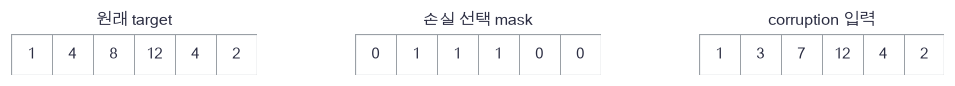

In [9]:
plot_corruption(corruption_clean,corruption_selected,corruption_hand)

🔍 **확인** · 선택 mask에는 세 칸이 표시되지만 실제 입력은 두 칸만 바뀝니다. 원래 target 배열은 그대로입니다. 아래 함수는 선택 난수와 대체 token을 인자로 받아 수치검산 때 corruption을 완전히 고정할 수 있습니다.

In [10]:
def corrupt_selected(ids, selected, branch_uniform, random_tokens, mask_id=3):
    """선택 위치의80%를MASK,10%를랜덤본문,10%를원래token으로 둡니다."""
    assert np.all(~selected | (ids>3)), 'PAD/BOS/EOS/MASK는 corruption 후보가 아닙니다'
    assert np.all(random_tokens[selected]>3), '랜덤 대체는 본문 어휘에서 뽑아야 합니다'
    result=ids.copy()
    mask_branch=selected & (branch_uniform<.8)
    random_branch=selected & (branch_uniform>=.8) & (branch_uniform<.9)
    result[mask_branch]=mask_id
    result[random_branch]=random_tokens[random_branch]
    return result

In [11]:
def mlm_training_batch(clean,rng,vocabulary_size):
    """문서마다 본문 한 위치를 균등 선택하여 고정 분모의 작은 MLM 배치를 만듭니다."""
    selected=np.zeros_like(clean,dtype=bool)
    for row in range(len(clean)):
        candidates=np.flatnonzero(clean[row]>3)
        assert len(candidates)>0, '문서마다 본문 token이 하나 이상 필요합니다'
        selected[row,candidates[rng.integers(len(candidates))]]=True
    branch=rng.uniform(size=clean.shape)
    random_tokens=rng.integers(4,vocabulary_size,size=clean.shape)
    corrupted=corrupt_selected(clean,selected,branch,random_tokens)
    return corrupted,selected

In [12]:
# 쓰는 것: corruption_clean, corruption_hand, corruption_random, corruption_selected, corruption_uniform (앞 절의 정의·실행 셀)
actual_corruption=corrupt_selected(corruption_clean,corruption_selected,corruption_uniform,corruption_random)
np.testing.assert_array_equal(actual_corruption,corruption_hand)  # 검산: MASK·랜덤·유지 세 경로
assert corruption_selected.sum()==3, '손실 분모는 바뀐2칸이 아니라 선택한3칸입니다'
assert np.sum(actual_corruption!=corruption_clean)==2, '실제로 바뀐 위치는2개입니다'
np.testing.assert_array_equal(corruption_clean,[[1,4,8,12,4,2]])  # 검산: 원래 정답 보존
sample_corrupted,sample_selected=mlm_training_batch(np.repeat(corruption_clean,5,axis=0),np.random.default_rng(4700),13)
assert np.all(sample_selected.sum(axis=1)==1), '문서마다 본문1개를 선택합니다'
assert not sample_selected[:,[0,5]].any(), 'BOS/EOS는 선택하지 않습니다'
print('80/10/10·원문 보존·선택 분모·특수 token 제외 검산 통과')

80/10/10·원문 보존·선택 분모·특수 token 제외 검산 통과


### ✏️ 연습 2 · 바뀌지 않은 선택 위치도 세기

selected의 True 개수 count를 채우세요.

In [13]:
def exercise_selection(selected):
    """바뀌지 않은 선택 위치도 세기의 계산을 완성합니다."""
    ### 구현할 내용: selected의 True 개수 count를 채우세요.
    raise NotImplementedError
    return count

In [14]:
def check_selection(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate(np.array([1,0,1,1],dtype=bool))==3, '원문 유지 여부와 관계없이 선택은3개입니다'
    print("연습 2 통과")

run_check(check_selection, exercise_selection, hint="바뀌지 않은 선택 위치도 세기의 수식과 축을 확인하세요.")

☐ exercise_selection: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 바뀌지 않은 선택 위치도 세기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
count = selected.sum()
```

</details>

## 🔑 3. 선택 CE를 전체 encoder로 역전파합니다

**이 절에서 가져갈 것:** logits 미분은 선택 위치에서만 시작하지만 문맥 token도 attention을 통해 기울기를 받습니다.

선택된 빈칸 하나의 정답 확률을 높이려면 주변 token의 표현도 바뀌어야 합니다. 손실을 계산하지 않은 위치의 **logits 미분**은0이지만 그 위치의 **입력 embedding 미분**이 항상0이라는 뜻은 아닙니다.

$$L_{MLM}=-\frac1M\sum_{n,t}s_{nt}\log p(u_{nt}\mid\widetilde U_n),\quad
G_{logits}=s\odot(P-onehot(u))/M,\quad M=\sum s.$$

$\widetilde U:(N,T)$는 손상된 입력, U는 원래 정답, s는 선택 mask입니다. attention valid mask와 s를 혼동하지 않습니다. 파라미터 E:(V,D), P:(32,D), attention 네 행렬:(D,D), FFN:(D,F),(F,D), LN의γ/β:(D,), head:(D,V)입니다. D=12,F=24를 사용합니다.

구조·LN·FFN·잔차 미분은45번과 같고 `causal=False`만으로 attention의 허용 영역을 바꿉니다. 실제 전체 함수 본문을 아래에 다시 둡니다. 모델을 밖의 helper로 숨기지 않습니다.

In [15]:
selected_probabilities=np.array([[.2,.5,.3],[.4,.4,.2],[.1,.2,.7]])
selected_positions=np.array([0,1,0],dtype=bool)
selected_target=np.array([0,2,1])
selected_delta=selected_probabilities.copy()
selected_delta[np.arange(3),selected_target]-=1
selected_delta*=selected_positions[:,None]/selected_positions.sum()

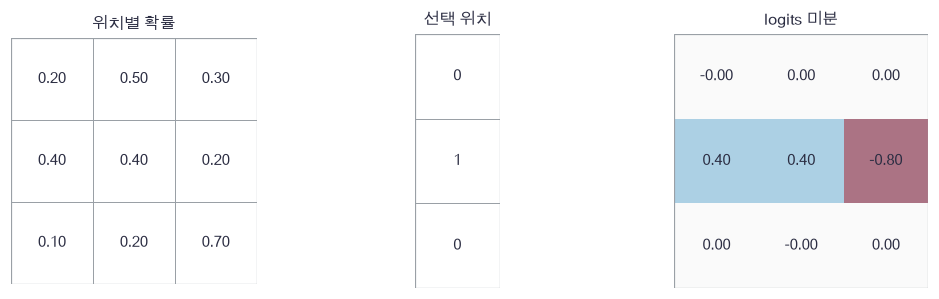

In [16]:
plot_selected_loss(selected_probabilities,selected_positions,selected_delta)

🔍 **확인** · 가운데 위치의 logits에서만 미분이 시작합니다. 아래 block에서는 Q/K/V 세 경로와 잔차가 그 신호를 다른 입력 위치로 전달합니다. 수치차분에서는 선택 위치·MASK·랜덤 대체를 다시 뽑지 않고 고정합니다.

> **코드** · `np.add.at`은 반복 입력 ID의 미분을 누적합니다. `reshape(-1,D)`는 배치와 위치를 합칩니다. `swapaxes(-1,-2)`는 attention의 마지막 두 축만 전치합니다. `weights * valid`는 선택되었더라도 PAD인 위치를 제외합니다. `_`는 사용하지 않는 반환값입니다.

In [17]:
def masked_softmax(scores, allowed):
    """마지막 key 축에서 허용한 점수만 정규화합니다. 전부 막힌 행은0입니다."""
    masked = np.where(allowed, scores, -np.inf)
    maximum = masked.max(axis=-1, keepdims=True)
    maximum = np.where(np.isfinite(maximum), maximum, 0.)
    exponential = np.exp(masked - maximum)
    total = exponential.sum(axis=-1, keepdims=True)
    return np.divide(exponential, total, out=np.zeros_like(exponential), where=total > 0)

In [18]:
def layernorm_forward(x, gamma, beta, epsilon=1e-5):
    """각 token의 마지막 D축을 정규화하고 affine 변환합니다."""
    centered = x - x.mean(axis=-1, keepdims=True)
    inverse = 1 / np.sqrt(np.mean(centered**2, axis=-1, keepdims=True) + epsilon)
    normalized = centered * inverse
    return normalized * gamma + beta, (normalized, inverse, gamma)

In [19]:
def layernorm_backward(upstream, cache):
    """epsilon을 포함한 LayerNorm의 입력·gamma·beta 미분을 반환합니다."""
    normalized, inverse, gamma = cache
    weighted = upstream * gamma
    dx = inverse * (weighted - weighted.mean(axis=-1, keepdims=True)
                    - normalized * (weighted * normalized).mean(axis=-1, keepdims=True))
    axes = tuple(range(upstream.ndim - 1))
    return dx, np.sum(upstream * normalized, axis=axes), np.sum(upstream, axis=axes)

In [20]:
def attention_forward(x, valid, p, causal=True):
    """한 head self-attention. x:(N,T,D), valid:(N,T); query/key padding을 모두 막습니다."""
    q, k, v = x @ p['Wq'], x @ p['Wk'], x @ p['Wv']
    scores = q @ k.swapaxes(-1,-2) / np.sqrt(x.shape[-1])
    allowed = valid[:,:,None] & valid[:,None,:]
    if causal:
        allowed = allowed & np.tril(np.ones((x.shape[1],x.shape[1]),dtype=bool))[None,:,:]
    probabilities = masked_softmax(scores, allowed)
    mixed = probabilities @ v
    return mixed @ p['Wo'], (x,q,k,v,probabilities,mixed)

In [21]:
def attention_backward(upstream, cache, p):
    """attention의 값 경로와 Q/K 점수 경로를 모두 누적합니다."""
    x,q,k,v,probabilities,mixed = cache
    width = x.shape[-1]
    delta = upstream @ p['Wo'].T
    dp = delta @ v.swapaxes(-1,-2)
    dv = probabilities.swapaxes(-1,-2) @ delta
    ds = probabilities * (dp - np.sum(dp * probabilities, axis=-1, keepdims=True))
    dq = (ds @ k) / np.sqrt(width)
    dk = (ds.swapaxes(-1,-2) @ q) / np.sqrt(width)
    flat = x.reshape(-1,width)
    gradients = {'Wo': mixed.reshape(-1,width).T @ upstream.reshape(-1,width),
                 'Wq': flat.T @ dq.reshape(-1,width), 'Wk': flat.T @ dk.reshape(-1,width),
                 'Wv': flat.T @ dv.reshape(-1,width)}
    dx = dq @ p['Wq'].T + dk @ p['Wk'].T + dv @ p['Wv'].T
    return dx, gradients

In [22]:
def init_decoder(vocabulary_size, width=12, hidden=24, max_length=32, seed=45, tied=False):
    """한 pre-LN decoder block과 최종 LN·head를 만듭니다. 모든 배열은 float64입니다."""
    rng = np.random.default_rng(seed)
    p = {'E': rng.normal(0,.15,(vocabulary_size,width)),
         'P': rng.normal(0,.08,(max_length,width))}
    for layer in ['1','2','f']:
        p['g'+layer] = np.ones(width)
        p['b'+layer] = np.zeros(width)
    for name in ['Wq','Wk','Wv','Wo']:
        p[name] = rng.normal(0,.25/np.sqrt(width),(width,width))
    p['W1'] = rng.normal(0,.5/np.sqrt(width),(width,hidden))
    p['c1'] = np.zeros(hidden)
    p['W2'] = rng.normal(0,.5/np.sqrt(hidden),(hidden,width))
    p['c2'] = np.zeros(width)
    if not tied:
        p['head'] = rng.normal(0,.3/np.sqrt(width),(width,vocabulary_size))
    p['bias'] = np.zeros(vocabulary_size)
    return p

In [23]:
def decoder_from_embeddings(x, valid, p, tied=False, causal=True):
    """연속 embedding 입력에서 LN→attention→잔차→LN→FFN→잔차→LN→head입니다."""
    # 쓰는 것: layernorm_forward (앞 절의 정의·실행 셀)
    first, cache1 = layernorm_forward(x,p['g1'],p['b1'])
    attended, attention_cache = attention_forward(first,valid,p,causal)
    residual = x + attended
    second, cache2 = layernorm_forward(residual,p['g2'],p['b2'])
    activation = np.tanh(second @ p['W1'] + p['c1'])
    hidden = residual + activation @ p['W2'] + p['c2']
    final, cachef = layernorm_forward(hidden,p['gf'],p['bf'])
    head = p['E'].T if tied else p['head']
    logits = final @ head + p['bias']
    return logits,(cache1,attention_cache,cache2,second,activation,cachef,final)

In [24]:
def decoder_feature_backward(dlogits, cache, p, tied=False):
    """연속 입력과 모든 block/head 배열을 미분합니다. tied이면 출력 E 경로도 더합니다."""
    # 쓰는 것: layernorm_backward (앞 절의 정의·실행 셀)
    # 1) head와 최종 정규화를 거슬러 갑니다.
    cache1,attention_cache,cache2,second,activation,cachef,final = cache
    width = final.shape[-1]
    gradients = {name:np.zeros_like(value) for name,value in p.items()}
    head_gradient = final.reshape(-1,width).T @ dlogits.reshape(-1,dlogits.shape[-1])
    if tied:
        gradients['E'] += head_gradient.T
        delta = dlogits @ p['E']
    else:
        gradients['head'] = head_gradient
        delta = dlogits @ p['head'].T
    gradients['bias'] = dlogits.sum(axis=(0,1))
    dh,gradients['gf'],gradients['bf'] = layernorm_backward(delta,cachef)
    # 2) FFN 경로와 직접 잔차 경로를 합칩니다.
    gradients['W2'] = activation.reshape(-1,activation.shape[-1]).T @ dh.reshape(-1,width)
    gradients['c2'] = dh.sum(axis=(0,1))
    da = (dh @ p['W2'].T) * (1-activation**2)
    gradients['W1'] = second.reshape(-1,width).T @ da.reshape(-1,da.shape[-1])
    gradients['c1'] = da.sum(axis=(0,1))
    dr,gradients['g2'],gradients['b2'] = layernorm_backward(da @ p['W1'].T,cache2)
    dr += dh
    # 3) attention의 모든 경로와 첫 잔차를 합칩니다.
    du,attention_gradients = attention_backward(dr,attention_cache,p)
    gradients.update(attention_gradients)
    dx,gradients['g1'],gradients['b1'] = layernorm_backward(du,cache1)
    return dx + dr, gradients

In [25]:
def decoder_forward(ids, valid, p, tied=False, causal=True):
    """정수 ID→학습 embedding+절대 위치→decoder. PAD 위치의 입력은0으로 만듭니다."""
    assert ids.shape[1] <= len(p['P']), '학습 위치 표의 최대 길이를 넘을 수 없습니다'
    embedded = (p['E'][ids] + p['P'][:ids.shape[1]]) * valid[:,:,None]
    logits,cache = decoder_from_embeddings(embedded,valid,p,tied,causal)
    return logits,(ids,valid,cache)

In [26]:
def decoder_backward(dlogits, full_cache, p, tied=False):
    """선택된 embedding 반복행과 배치가 공유하는 위치행까지 누적합니다."""
    ids,valid,cache = full_cache
    dx,gradients = decoder_feature_backward(dlogits,cache,p,tied)
    dx *= valid[:,:,None]
    np.add.at(gradients['E'],ids.ravel(),dx.reshape(-1,dx.shape[-1]))
    gradients['P'][:ids.shape[1]] += dx.sum(axis=0)
    return gradients,dx

In [27]:
def token_cross_entropy(logits, targets, weights):
    """선택한 target만 가중 평균합니다. logprob 전체와 정확한 dlogits를 반환합니다."""
    shifted = logits - logits.max(axis=-1,keepdims=True)
    logprob = shifted - np.log(np.exp(shifted).sum(axis=-1,keepdims=True))
    denominator = weights.sum()
    assert denominator > 0, '손실에 포함할 target이 적어도 하나 필요합니다'
    assert np.all(weights >= 0), '손실 가중치는 음수가 아니어야 합니다'
    rows = np.arange(targets.size)
    selected = logprob.reshape(-1,logits.shape[-1])[rows,targets.ravel()].reshape(targets.shape)
    loss = -np.sum(selected * weights) / denominator
    delta = np.exp(logprob).reshape(-1,logits.shape[-1])
    delta[rows,targets.ravel()] -= 1
    delta *= weights.ravel()[:,None] / denominator
    return float(loss),delta.reshape(logits.shape),logprob

In [28]:
def decoder_loss(ids, targets, valid, p, tied=False, weights=None, causal=True):
    """모델 전체와 선택 target CE를 연결합니다. 입력 유효 mask와 loss mask를 구분합니다."""
    logits,cache = decoder_forward(ids,valid,p,tied,causal)
    actual_weights = valid if weights is None else weights * valid
    loss,delta,logprob = token_cross_entropy(logits,targets,actual_weights)
    gradients,dx = decoder_backward(delta,cache,p,tied)
    return loss,gradients,logprob,dx

In [29]:
def adam_state(p):
    """모든 학습 배열에 독립인 Adam 상태를 만듭니다."""
    return {'m':{name:np.zeros_like(value) for name,value in p.items()},
            'v':{name:np.zeros_like(value) for name,value in p.items()},'t':0}

In [30]:
def adam_update(p, gradients, state, learning_rate=.01):
    """Adam의 모멘트와 편향 보정으로 지정된 배열만 갱신합니다."""
    state['t'] += 1
    for name in gradients:
        state['m'][name] = .9*state['m'][name] + .1*gradients[name]
        state['v'][name] = .999*state['v'][name] + .001*gradients[name]**2
        first = state['m'][name]/(1-.9**state['t'])
        second = state['v'][name]/(1-.999**state['t'])
        p[name] -= learning_rate*first/(np.sqrt(second)+1e-8)

In [31]:
def language_batch(documents, pad=0, bos=1, eos=2):
    """정수 문서 목록을 BOS 입력·EOS 타깃으로 이동하고 오른쪽 PAD를 채웁니다."""
    length = max(len(document)+1 for document in documents)
    ids = np.full((len(documents),length),pad,dtype=int)
    targets = np.full_like(ids,pad)
    valid = np.zeros_like(ids,dtype=bool)
    for index,document in enumerate(documents):
        count = len(document)+1
        ids[index,:count] = [bos]+list(document)
        targets[index,:count] = list(document)+[eos]
        valid[index,:count] = True
    return ids,targets,valid

In [32]:
def train_decoder(train_batch, valid_batch, vocabulary_size, seed=45, steps=300, tied=False):
    """고정 300회 미니배치 Adam 후 반환합니다. valid는 기록만 하고 선택하지 않습니다."""
    # 쓰는 것: decoder_loss, init_decoder (앞 절의 정의·실행 셀)
    p = init_decoder(vocabulary_size,seed=seed,tied=tied)
    state = adam_state(p)
    rng = np.random.default_rng(seed+100)
    history = []
    for step in range(steps+1):
        if step % 100 == 0:
            train_loss = decoder_loss(*train_batch,p,tied)[0]
            valid_loss = decoder_loss(*valid_batch,p,tied)[0]
            history.append([step,train_loss,valid_loss])
        if step == steps:
            break
        index = rng.integers(0,len(train_batch[0]),size=8)
        batch = tuple(array[index] for array in train_batch)
        _,gradients,_,_ = decoder_loss(*batch,p,tied)
        adam_update(p,gradients,state)
    return p,np.asarray(history)

In [33]:
def check_mlm_gradients():
    """고정 corruption의 모든 파라미터와 선택 logits·문맥 입력 미분을 검사합니다."""
    # 쓰는 것: decoder_forward, decoder_loss, init_decoder, token_cross_entropy (앞 절의 정의·실행 셀)
    p=init_decoder(7,width=3,hidden=4,max_length=5,seed=4702)
    ids=np.array([[1,3,4,2,0],[1,4,3,2,0]])
    original=np.array([[1,5,4,2,0],[1,4,6,2,0]])
    valid=ids!=0
    selected=ids==3
    loss,gradients,_,dx=decoder_loss(ids,original,valid,p,weights=selected,causal=False)
    def objective():
        """원문·corruption·선택 위치를 고정한 MLM 목적입니다."""
        return decoder_loss(ids,original,valid,p,weights=selected,causal=False)[0]
    maximum=0.
    for name,value in p.items():
        numeric=numerical_gradient(objective,value)
        np.testing.assert_allclose(gradients[name],numeric,atol=3e-7,rtol=2e-4)  # 검산: 전체 MLM 파라미터 손미분 = 중심차분
        maximum=max(maximum,float(np.max(np.abs(gradients[name]-numeric))))
    logits,_=decoder_forward(ids,valid,p,causal=False)
    _,delta,_=token_cross_entropy(logits,original,selected)
    assert np.all(delta[~selected]==0), '선택되지 않은 logits 미분은0입니다'
    assert np.max(np.abs(dx[0,2]))>1e-8, '이 고정 예의 오른쪽 문맥은 attention으로 미분을 받습니다'
    assert np.all(dx[~valid]==0), 'PAD 입력의 미분은0입니다'
    return maximum

In [34]:
print('고정 corruption 전체 미분 최대오차:',check_mlm_gradients())

고정 corruption 전체 미분 최대오차: 3.5242724298785444e-10


### ✏️ 연습 3 · 선택 위치만 logits 미분 남기기

delta와 selected로 masked_delta를 채우세요.

In [35]:
def exercise_lossmask(delta, selected):
    """선택 위치만 logits 미분 남기기의 계산을 완성합니다."""
    ### 구현할 내용: delta와 selected로 masked_delta를 채우세요.
    raise NotImplementedError
    return masked_delta

In [36]:
def check_lossmask(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.ones((3,2)),np.array([0,1,0])),[[0,0],[1,1],[0,0]])  # 검산: 선택 위치 한 행만 남기기
    print("연습 3 통과")

run_check(check_lossmask, exercise_lossmask, hint="선택 위치만 logits 미분 남기기의 수식과 축을 확인하세요.")

☐ exercise_lossmask: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 선택 위치만 logits 미분 남기기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
masked_delta = delta * selected[:,None]
```

</details>

## 🔑 4. 같은 정답이어도 주는 정보가 다릅니다

**이 절에서 가져갈 것:** MLM의 빈칸 복원과 causal next-token 학습을 실제 실행하되 서로 다른 조건부 문제임을 명시합니다.

첫 색을 맞힐 때 MLM은 `[BOS,MASK,pear,is,red,EOS]`를 받고, 자기회귀 모델은 `[BOS]`만 받습니다. 뒤의 색을 미리 주는 문제의 NLL이 낮다고 더 좋은 자기회귀 언어모델이라는 결론을 내릴 수 없습니다.

네 색×네 과일의 고유 문장16개를 seed4701로 섞어 train12/valid2/test2로 나눕니다. 네 본문 token의 패턴은 `[color,fruit,is,color]`입니다. 색은ID4–7, 과일은8–11, `is`는12입니다. 두 모델의 구조·초기 seed47·Adam.01·300회·배치8은 같고 목적과 입력 구성은 다릅니다. MLM은 매 문서1개 선택, AR은 EOS까지 모두 예측하므로 **손실 target 수가 같은 실험은 아닙니다**.

MLM의 고정 평가에서는 첫 색 하나만 항상 MASK로 바꿉니다. 원래 token 유지10% 때문에 쉬워진 평가를 하는 것이 아닙니다. valid는 기록만 하고 test로 설정을 선택하지 않습니다.

In [37]:
information_mlm=np.array([1,3,8,12,4,2])
information_ar=np.array([1])
information_answer=4

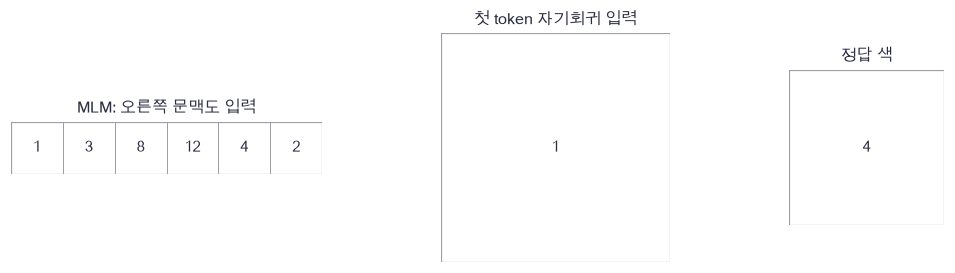

In [38]:
plot_information_access(information_mlm,information_ar,information_answer)

🔍 **확인** · 왼쪽에는 마지막 색4가 입력에 남고, 가운데에는 색에 대한 단서가 없습니다. 조건부 정보의 차이를 그대로 보이기 위한 실험이며 두 NLL을 보편적 성능 순위로 비교하지 않습니다.

> **코드** · `np.random.default_rng(seed)`는 독립 난수열을 만듭니다. `rng.permutation(16)`은 문장번호를 중복 없이 섞습니다. `p['E']`는 학습 embedding 표입니다. `*batch`는 세 배열 인자를 풉니다.

In [39]:
def mlm_score(clean,p,position=1):
    """고정 위치를 항상MASK로 가린 평가에서 선택 위치 NLL·정확도를 구합니다."""
    # 쓰는 것: decoder_loss (앞 절의 정의·실행 셀)
    corrupted=clean.copy()
    corrupted[:,position]=3
    weights=np.zeros_like(clean,dtype=bool)
    weights[:,position]=True
    loss,_,logprob,_=decoder_loss(corrupted,clean,clean!=0,p,weights=weights,causal=False)
    prediction=logprob.argmax(axis=-1)
    accuracy=np.mean(prediction[:,position]==clean[:,position])
    return loss,float(accuracy),prediction[:,position]

In [40]:
def train_mlm(train,valid,vocabulary_size,steps=300,seed=47):
    """선택 위치만 CE로 학습합니다. corruption과 모델 초기값의 난수를 분리합니다."""
    # 쓰는 것: adam_state, adam_update, decoder_loss, init_decoder, mlm_training_batch (앞 절의 정의·실행 셀)
    p=init_decoder(vocabulary_size,seed=seed)
    state=adam_state(p)
    rng=np.random.default_rng(seed+1000)
    history=[]
    for step in range(steps+1):
        if step%100==0:
            history.append([step,mlm_score(train,p)[0],mlm_score(valid,p)[0]])
        if step==steps:
            break
        index=rng.integers(0,len(train),size=8)
        clean=train[index]
        corrupted,selected=mlm_training_batch(clean,rng,vocabulary_size)
        _,gradients,_,_=decoder_loss(corrupted,clean,clean!=0,p,weights=selected,causal=False)
        adam_update(p,gradients,state)
    return p,np.asarray(history)

In [41]:
# 쓰는 것: language_batch, train_decoder (앞 절의 정의·실행 셀)
all_sequences=np.array([[1,color,fruit,12,color,2] for color in range(4,8) for fruit in range(8,12)])
order=np.random.default_rng(4701).permutation(16)
train_sequences=all_sequences[order[:12]]
valid_sequences=all_sequences[order[12:14]]
test_sequences=all_sequences[order[14:]]
assert not set(map(tuple,train_sequences))&set(map(tuple,test_sequences)), '고유 문장 train/test는 겹치지 않습니다'
mlm_parameters,mlm_history=train_mlm(train_sequences,valid_sequences,13)
ar_train=language_batch([row[1:-1].tolist() for row in train_sequences])
ar_valid=language_batch([row[1:-1].tolist() for row in valid_sequences])
ar_test=language_batch([row[1:-1].tolist() for row in test_sequences])
ar_parameters,ar_history=train_decoder(ar_train,ar_valid,13,seed=47)
print('같은 모델 파라미터 수:',sum(value.size for value in mlm_parameters.values()))
print('MLM 선택 target 제시:',300*8,'· AR 유효 target 제시:',300*8*5)

같은 모델 파라미터 수: 1969
MLM 선택 target 제시: 2400 · AR 유효 target 제시: 12000


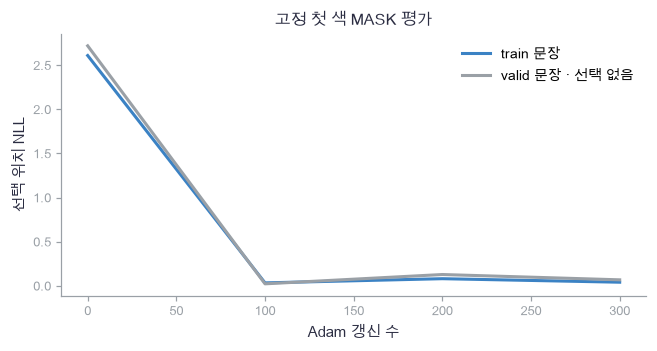

In [42]:
plot_mlm_learning(mlm_history)

In [43]:
# 쓰는 것: decoder_loss, mlm_score (앞 절의 정의·실행 셀)
for name,clean in [('train',train_sequences),('valid',valid_sequences),('test',test_sequences)]:
    loss,accuracy,prediction=mlm_score(clean,mlm_parameters)
    print('MLM',name,'첫 색 MASK NLL',round(loss,4),'accuracy',accuracy)
for name,batch in [('train',ar_train),('valid',ar_valid),('test',ar_test)]:
    loss,_,logprob,_=decoder_loss(*batch,ar_parameters)
    first_nll=-logprob[:,0,:][np.arange(len(batch[0])),batch[1][:,0]].mean()
    first_accuracy=np.mean(logprob[:,0].argmax(axis=-1)==batch[1][:,0])
    print('AR',name,'모든 next-token NLL',round(loss,4),'· 첫 색 NLL',round(first_nll,4),'accuracy',first_accuracy)
assert np.isfinite(mlm_history).all(), 'MLM 평가 기록은 유한해야 합니다'
assert np.isfinite(ar_history).all(), 'AR 평가 기록도 유한해야 합니다'

MLM train 첫 색 MASK NLL 0.0408 accuracy 1.0
MLM valid 첫 색 MASK NLL 0.0679 accuracy 1.0
MLM test 첫 색 MASK NLL 0.0137 accuracy 1.0
AR train 모든 next-token NLL 0.5352 · 첫 색 NLL 1.4263 accuracy 0.25
AR valid 모든 next-token NLL 0.994 · 첫 색 NLL 1.6557 accuracy 0.0
AR test 모든 next-token NLL 0.9812 · 첫 색 NLL 1.1969 accuracy 0.5


🔍 **확인** · 첫 색 복원은 오른쪽 반복 색이 있는 단순 과제입니다. test 두 문장의 높은 정확도도 일반 언어 이해의 증거로 확대하지 않습니다. MLM의 선택 CE는 자기회귀 확률 분해가 아니므로 exp(MLM loss)를45번의 문장 PPL과 같은 지표로 보고하지 않습니다.

### ✏️ 연습 4 · 정답 앞부분만 꺼내기

next-token 위치 t를 예측할 때 이미 주어진 ids의 prefix를 채우세요.

In [44]:
def exercise_prefix(ids, t):
    """정답 앞부분만 꺼내기의 계산을 완성합니다."""
    ### 구현할 내용: next-token 위치 t를 예측할 때 이미 주어진 ids의 prefix를 채우세요.
    raise NotImplementedError
    return prefix

In [45]:
def check_prefix(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate([1,4,8,12,4],2)==[1,4], '세 번째 token을 맞힐 때 앞 두 token만 줍니다'
    print("연습 4 통과")

run_check(check_prefix, exercise_prefix, hint="정답 앞부분만 꺼내기의 수식과 축을 확인하세요.")

☐ exercise_prefix: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 정답 앞부분만 꺼내기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
prefix = ids[:t]
```

</details>

## 🔑 5. 빈칸 복원은 자유 생성과 다른 사용법입니다

**이 절에서 가져갈 것:** 한 MASK를 채우는 조건부 예측과 문장 전체를 생성하는 절차를 구분하고 오른쪽 문맥·padding 경계를 검사합니다.

학습에 없던 색–과일 조합에서 첫 색을 가린 뒤 모델이 채우게 합니다. 정답은 비교용으로만 보관하고 forward에는 MASK가 들어갑니다. 나머지 token은 고정합니다. 여러 빈칸을 차례로 채우는 방법도 만들 수 있지만 순서에 따라 다른 결과가 날 수 있고, 이 단일 조건부 학습이 자동으로 정규화된 문장 결합분포를 주는 것은 아닙니다.

아래 개념 그림은 실제 test 문장과 실제 모델의 한 위치 logits argmax를 이용합니다. 이 그림의 예측은 계산 셀에서 수행하고 helper는 받은 배열만 표시합니다.

In [46]:
# 쓰는 것: decoder_forward, mlm_parameters, test_sequences (앞 절의 정의·실행 셀)
fill_original=test_sequences[0].copy()
fill_masked=fill_original.copy()
fill_masked[1]=3
fill_logits,_=decoder_forward(fill_masked[None,:],np.ones((1,6),dtype=bool),mlm_parameters,causal=False)
fill_scores=fill_logits[0,1].copy()
fill_scores[:4]=-np.inf
fill_prediction=fill_masked.copy()
fill_prediction[1]=int(np.argmax(fill_scores))

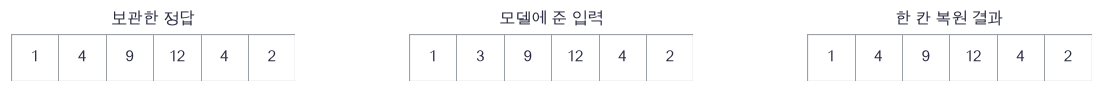

In [47]:
plot_fill(fill_original,fill_masked,fill_prediction)

🔍 **확인** · 왼쪽 정답의 첫 색은 모델 입력에서 지워졌습니다. 오른쪽은 모델이 채운 한 칸입니다. 이 경우 마지막 색을 읽을 수 있지만, 과일 칸 자체를 가리면 같은 규칙만으로 과일을 유일하게 정할 수 없습니다. 입력 정보가 충분한지와 학습 성능을 함께 읽습니다.

In [48]:
def fill_one_mask(ids,p,position):
    """선택한 MASK 한 칸을 양방향 문맥에서 greedy 예측합니다. 다른 칸은 고정합니다."""
    # 쓰는 것: decoder_forward (앞 절의 정의·실행 셀)
    assert ids[position]==3, '채울 위치는MASK여야 합니다'
    logits,_=decoder_forward(np.array([ids]),np.array([ids])!=0,p,causal=False)
    scores=logits[0,position].copy()
    scores[:4]=-np.inf
    result=list(ids)
    result[position]=int(np.argmax(scores))
    return result

In [49]:
# 쓰는 것: decoder_forward, mlm_parameters, test_sequences (앞 절의 정의·실행 셀)
np.testing.assert_array_equal(fill_one_mask(fill_masked.tolist(),mlm_parameters,1),fill_prediction)  # 검산: 함수의 실제 빈칸 복원 = 직접 계산
for clean in test_sequences:
    masked=clean.copy()
    masked[1]=3
    restored=fill_one_mask(masked.tolist(),mlm_parameters,1)
    print('test 정답',clean.tolist(),'· 입력',masked.tolist(),'· 복원',restored)
probe=np.array([[1,3,8,12,4,2,0]])
probe_valid=probe!=0
changed=probe.copy()
changed[0,4]=7
causal_before,_=decoder_forward(probe,probe_valid,mlm_parameters,causal=True)
causal_after,_=decoder_forward(changed,probe_valid,mlm_parameters,causal=True)
np.testing.assert_allclose(causal_before[:,:4],causal_after[:,:4],atol=1e-12)  # 검산: causal 과거는 오른쪽 token 변경에 불변
bidirectional_before,_=decoder_forward(probe,probe_valid,mlm_parameters,causal=False)
bidirectional_after,_=decoder_forward(changed,probe_valid,mlm_parameters,causal=False)
print('이 학습 모델의 오른쪽 색 변경에 따른 MASK logits 최대차이:',np.max(np.abs(bidirectional_before[0,1]-bidirectional_after[0,1])))
changed_padding=probe.copy()
changed_padding[0,-1]=9
np.testing.assert_allclose(decoder_forward(changed_padding,probe_valid,mlm_parameters,causal=False)[0],bidirectional_before,atol=1e-12)  # 검산: 양방향에서도 PAD값 불변
print('단일 빈칸 복원·읽기 범위·PAD 값 검산 통과')

test 정답 [1, 4, 9, 12, 4, 2] · 입력 [1, 3, 9, 12, 4, 2] · 복원 [1, 4, 9, 12, 4, 2]
test 정답 [1, 7, 10, 12, 7, 2] · 입력 [1, 3, 10, 12, 7, 2] · 복원 [1, 7, 10, 12, 7, 2]
이 학습 모델의 오른쪽 색 변경에 따른 MASK logits 최대차이: 7.2786708941682505
단일 빈칸 복원·읽기 범위·PAD 값 검산 통과


📎 **참고** · 원리와80/10/10 규칙의 출처는 [BERT 원문 3.1절](https://arxiv.org/pdf/1810.04805)입니다. 원문의15% 선택률, 다층 구조, NSP 목적과 이 교육 실험의 차이를 앞에서 명시했습니다. 이 notebook의 생성 사용은 **한 MASK 조건부 복원**이며46번의 causal sampling이나 KV cache를 그대로 적용하지 않습니다.

### ✏️ 연습 5 · 한 칸만 복원하고 나머지는 보존하기

ids의 사본 result에서 position을 prediction으로 바꾸세요.

In [50]:
def exercise_fill(ids, position, prediction):
    """한 칸만 복원하고 나머지는 보존하기의 계산을 완성합니다."""
    result = ids.copy()
    ### 구현할 내용: ids의 사본 result에서 position을 prediction으로 바꾸세요.
    raise NotImplementedError
    return result

In [51]:
def check_fill(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate([1,3,8,2],1,4)==[1,4,8,2], '선택한 MASK 한 칸만 바꿉니다'
    print("연습 5 통과")

run_check(check_fill, exercise_fill, hint="한 칸만 복원하고 나머지는 보존하기의 수식과 축을 확인하세요.")

☐ exercise_fill: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 한 칸만 복원하고 나머지는 보존하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
result[position] = prediction
```

</details>

## ✏️ 끝 연습 · A–D

읽기 mask·선택 mask·손실 target을 각각 확인합니다.

### ✏️ 연습 A · 특수 token 제외하기

ids의 본문 여부 eligible을 채우세요.

In [52]:
def exercise_eligible(ids):
    """특수 token 제외하기의 계산을 완성합니다."""
    ### 구현할 내용: ids의 본문 여부 eligible을 채우세요.
    raise NotImplementedError
    return eligible

In [53]:
def check_eligible(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.array([0,1,2,3,4,8])),[0,0,0,0,1,1])  # 검산: 특수ID0–3 제외
    print("연습 A 통과")

run_check(check_eligible, exercise_eligible, hint="특수 token 제외하기의 수식과 축을 확인하세요.")

☐ exercise_eligible: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 특수 token 제외하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
eligible = ids > 3
```

</details>

### ✏️ 연습 B · MASK 대체 경로 고르기

selected와 uniform으로80% MASK 경로 mask_branch를 채우세요.

In [54]:
def exercise_branch(selected, uniform):
    """MASK 대체 경로 고르기의 계산을 완성합니다."""
    ### 구현할 내용: selected와 uniform으로80% MASK 경로 mask_branch를 채우세요.
    raise NotImplementedError
    return mask_branch

In [55]:
def check_branch(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.array([1,1,0],dtype=bool),np.array([.1,.9,.2])),[1,0,0])  # 검산: 선택 여부와 대체 구간 모두 필요
    print("연습 B 통과")

run_check(check_branch, exercise_branch, hint="MASK 대체 경로 고르기의 수식과 축을 확인하세요.")

☐ exercise_branch: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: MASK 대체 경로 고르기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
mask_branch = selected & (uniform < .8)
```

</details>

### ✏️ 연습 C · 선택한 평균 손실 계산하기

nll과 selected에서 mean_loss를 계산하세요.

In [56]:
def exercise_selectedmean(nll, selected):
    """선택한 평균 손실 계산하기의 계산을 완성합니다."""
    ### 구현할 내용: nll과 selected에서 mean_loss를 계산하세요.
    raise NotImplementedError
    return mean_loss

In [57]:
def check_selectedmean(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate(np.array([100.,2.,4.]),np.array([0,1,1]))==3., '선택된2개만 평균합니다'
    print("연습 C 통과")

run_check(check_selectedmean, exercise_selectedmean, hint="선택한 평균 손실 계산하기의 수식과 축을 확인하세요.")

☐ exercise_selectedmean: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 선택한 평균 손실 계산하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
mean_loss = np.sum(nll * selected) / selected.sum()
```

</details>

### ✏️ 연습 D · MLM에서 PAD를 여전히 제외하기

selected와 valid의 교집합 weights를 채우세요.

In [58]:
def exercise_validloss(selected, valid):
    """MLM에서 PAD를 여전히 제외하기의 계산을 완성합니다."""
    ### 구현할 내용: selected와 valid의 교집합 weights를 채우세요.
    raise NotImplementedError
    return weights

In [59]:
def check_validloss(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.array([1,1,1],dtype=bool),np.array([1,1,0],dtype=bool)),[1,1,0])  # 검산: PAD 손실0
    print("연습 D 통과")

run_check(check_validloss, exercise_validloss, hint="MLM에서 PAD를 여전히 제외하기의 수식과 축을 확인하세요.")

☐ exercise_validloss: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: MLM에서 PAD를 여전히 제외하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
weights = selected & valid
```

</details>

## ✏️ 준비도 · 설명·수식·구현·변형 검산

- **설명:** MLM 선택 mask와 attention 허용 mask, 바뀐 위치 mask가 왜 서로 다른가요?
- **수식:** 선택 CE의 분모와 logits 미분을 쓰고, 선택하지 않은 입력에도 기울기가 갈 수 있는 경로를 설명할 수 있나요?
- **구현:** corruption을 고정해 양방향 block의 모든 파라미터를 중심차분하고 MASK를 실제 복원할 수 있나요?
- **변형 검산:** 오른쪽 문맥·PAD 값·선택 유지10%·빈칸 위치를 바꾸었을 때 어떤 출력과 미분이 달라지는지 확인할 수 있나요?

48번은 next-token decoder로 돌아가 답변 위치에만 손실을 주는 SFT와 학습할 파라미터를 제한하는 LoRA를 구현합니다.